# Hypothesis 2: During Kiel Week, the bakery sells more rolls

**Author:** Lennard · **Canvas:** hypothesis 2 (block 2)

**Purpose.** We check whether **rolls (product group 2)** sell more during **Kiel Week** (*Kieler Woche*) than in normal weeks.

**How we test it**
1. **Main test: whole weeks.** For each year we compare the average daily roll turnover in the **Kiel Week week** (Monday to Sunday) with the **normal weeks** around it. A whole week contains every weekday exactly once, so the strong weekend days cannot distort the comparison. Each year gives **one pair** (Kiel Week vs. normal), so we get 5 pairs, one per Kiel Week. That respects that we have only 5 Kiel Weeks, not 45 independent days.
2. **Cross-check: regression.** A regression compares every Kiel Week day with normal days of the same weekday and year, all at once.
3. **Detail: which weekdays.** A bar chart shows the average for each weekday.

**One-sided test.** The hypothesis says rolls sell *more*, and this direction was fixed before we looked at the data. So the tests only ask "is Kiel Week higher?" (one-sided). A two-sided test would also count "lower" as a result. It is more cautious, but with only 5 years it is harder to pass.

## 1. Setup and data

We read the sales and Kiel Week files directly from the course repository (raw data is never changed). The Kiel Week file only lists Kiel Week days, so after joining, all other days get `KielerWoche = 0` (decision in `DECISIONS.md`, 2026-11-23). Then we check that the join did what we expect.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

BASE_URL = "https://raw.githubusercontent.com/opencampus-sh/intro-to-data-science-and-ml/main/data/bakery/"
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]  # Mon -> Sun (team convention)

# Chart style. Colours checked for colour-vision deficiency: normal = blue, Kiel Week = orange
C_NORMAL, C_KW = "#2a78d6", "#eb6834"
INK, INK_MUTED, GRID, BG = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "axes.edgecolor": GRID,
    "axes.labelcolor": INK_MUTED, "text.color": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "font.size": 10,
})

def mean_ci(values, level=0.95):
    """Mean and half-width of the t-based 95 % confidence interval of the mean."""
    sem = values.std(ddof=1) / np.sqrt(len(values))  # standard error of the mean
    return values.mean(), stats.t.ppf((1 + level) / 2, len(values) - 1) * sem

sales = pd.read_csv(BASE_URL + "umsatzdaten_gekuerzt.csv", parse_dates=["Datum"])
kiwo = pd.read_csv(BASE_URL + "kiwo.csv", parse_dates=["Datum"])

df = sales.merge(kiwo, on="Datum", how="left")
df["KielerWoche"] = df["KielerWoche"].fillna(0).astype(int)
df["Weekday"] = pd.Categorical(df["Datum"].dt.day_name(), categories=WEEKDAYS, ordered=True)
df["Year"] = df["Datum"].dt.year

# Checks
assert len(df) == len(sales) == 9334, "join changed the number of rows"
assert set(df["KielerWoche"].unique()) <= {0, 1}
kw_days = df.loc[df["KielerWoche"] == 1, "Datum"].drop_duplicates()
assert len(kw_days) == 45, f"expected 45 Kiel Week days, got {len(kw_days)}"
assert sorted(kw_days.dt.year.unique()) == [2014, 2015, 2016, 2017, 2018]

rolls_all = df[df["Warengruppe"] == 2].set_index("Datum")["Umsatz"]  # one value per day
kw_periods = kw_days.groupby(kw_days.dt.year).agg(start="min", end="max")
kw_periods.index.name = "Year"
kw_periods["start weekday"] = kw_periods["start"].dt.day_name()
kw_periods["end weekday"] = kw_periods["end"].dt.day_name()
print("Checks passed: 9,334 rows, 45 Kiel Week days in 5 years.")
kw_periods

Checks passed: 9,334 rows, 45 Kiel Week days in 5 years.


,start,end,start weekday,end weekday
Year,,,,
2014,2014-06-21,2014-06-29,Saturday,Sunday
2015,2015-06-20,2015-06-28,Saturday,Sunday
2016,2016-06-18,2016-06-26,Saturday,Sunday
2017,2017-06-17,2017-06-25,Saturday,Sunday
2018,2018-06-16,2018-06-24,Saturday,Sunday


## 2. Main test: Kiel Week week vs. normal weeks

The table above shows that every Kiel Week runs from a **Saturday to the Sunday 8 days later** (9 days). We define:
- **Kiel Week week** = the last 7 Kiel Week days, Monday to Sunday.
- **Normal weeks** = 4 Monday-to-Sunday weeks of the same year: the 2 weeks right **after** Kiel Week, and the 2nd and 3rd week **before** it. The week directly before is skipped, because its Saturday and Sunday already belong to Kiel Week.

Because the skipped week contains Kiel Week's first Saturday and Sunday, those two days do not enter the week test. The first table below lists the exact weeks used in each year.

For each week we compute the **average turnover per day**. We use the average rather than the total because two normal weeks have one closed day (2016-07-07 and 2017-07-04).

In [2]:
rows, week_dates = [], []
for year, p in kw_periods.iterrows():
    kw_monday = p["end"] - pd.Timedelta(days=6)
    week_means = {}
    for k in [-3, -2, 0, 1, 2]:  # week number relative to the Kiel Week week (0)
        first = kw_monday + pd.Timedelta(weeks=k)
        week = rolls_all[first : first + pd.Timedelta(days=6)]
        assert len(week) >= 6, f"{year}, week {k}: only {len(week)} days with sales"
        assert first.day_name() == "Monday"
        week_means[k] = week.mean()
    rows.append({
        "Year": year,
        "Normal weeks (€ per day)": np.mean([week_means[k] for k in [-3, -2, 1, 2]]),
        "Kiel Week (€ per day)": week_means[0],
    })
    span = lambda k: (f"{(kw_monday + pd.Timedelta(weeks=k)):%d.%m.}–"
                      f"{(kw_monday + pd.Timedelta(weeks=k, days=6)):%d.%m.}")
    week_dates.append({"Year": year, "Normal week 1": span(-3), "Normal week 2": span(-2),
                       "(skipped)": span(-1), "Kiel Week week": span(0),
                       "Normal week 3": span(1), "Normal week 4": span(2)})

weeks = pd.DataFrame(rows).set_index("Year")
weeks["Difference (%)"] = 100 * (weeks["Kiel Week (€ per day)"] / weeks["Normal weeks (€ per day)"] - 1)
display(pd.DataFrame(week_dates).set_index("Year"))  # which weeks were compared
weeks.round(1)

,Normal week 1,Normal week 2,(skipped),Kiel Week week,Normal week 3,Normal week 4
Year,,,,,,
2014,02.06.–08.06.,09.06.–15.06.,16.06.–22.06.,23.06.–29.06.,30.06.–06.07.,07.07.–13.07.
2015,01.06.–07.06.,08.06.–14.06.,15.06.–21.06.,22.06.–28.06.,29.06.–05.07.,06.07.–12.07.
2016,30.05.–05.06.,06.06.–12.06.,13.06.–19.06.,20.06.–26.06.,27.06.–03.07.,04.07.–10.07.
2017,29.05.–04.06.,05.06.–11.06.,12.06.–18.06.,19.06.–25.06.,26.06.–02.07.,03.07.–09.07.
2018,28.05.–03.06.,04.06.–10.06.,11.06.–17.06.,18.06.–24.06.,25.06.–01.07.,02.07.–08.07.


,Normal weeks (€ per day),Kiel Week (€ per day),Difference (%)
Year,,,
2014,519.1,621.3,19.7
2015,443.4,530.4,19.6
2016,406.1,519.5,27.9
2017,414.9,473.6,14.1
2018,423.0,498.0,17.7


**Paired t-test.** "Paired" means each Kiel Week is compared with the normal weeks of **its own year**. Differences between years (e.g. a generally stronger year) therefore do not matter. The test asks whether the 5 differences are, on average, clearly above zero.

In [3]:
paired = stats.ttest_rel(weeks["Kiel Week (€ per day)"], weeks["Normal weeks (€ per day)"], alternative="greater")
print(f"Average difference: {weeks['Difference (%)'].mean():+.1f} % "
      f"(years with an increase: {(weeks['Difference (%)'] > 0).sum()} of {len(weeks)})")
print(f"Paired t-test, one-sided: t = {paired.statistic:.2f}, p = {paired.pvalue:.4f}")

Average difference: +19.8 % (years with an increase: 5 of 5)
Paired t-test, one-sided: t = 9.03, p = 0.0004


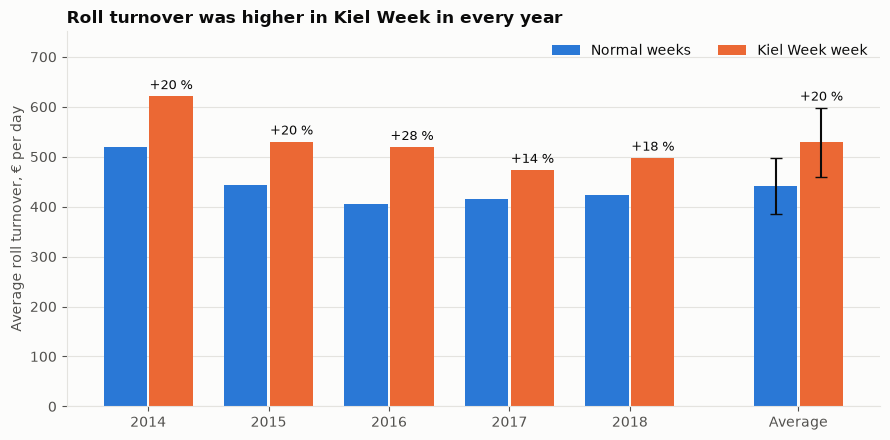

In [4]:
# Bars per year, plus the average over the 5 years with a 95 % confidence interval
normal_avg, normal_ci = mean_ci(weeks["Normal weeks (€ per day)"])
kw_avg, kw_ci = mean_ci(weeks["Kiel Week (€ per day)"])
labels = [str(y) for y in weeks.index] + ["Average"]
normal_vals = list(weeks["Normal weeks (€ per day)"]) + [normal_avg]
kw_vals = list(weeks["Kiel Week (€ per day)"]) + [kw_avg]
diffs = list(weeks["Difference (%)"]) + [100 * (kw_avg / normal_avg - 1)]

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(labels)).astype(float)
x[-1] += 0.4  # small gap before the average group
w = 0.38
ax.bar(x - w / 2, normal_vals, width=w - 0.02, color=C_NORMAL, label="Normal weeks")
ax.bar(x + w / 2, kw_vals, width=w - 0.02, color=C_KW, label="Kiel Week week")
ax.errorbar([x[-1] - w / 2, x[-1] + w / 2], [normal_avg, kw_avg], yerr=[normal_ci, kw_ci],
            fmt="none", ecolor=INK, elinewidth=1.5, capsize=4)
for xi, v, d, is_avg in zip(x, kw_vals, diffs, [False] * len(weeks) + [True]):
    top = v + (kw_ci if is_avg else 0)
    ax.text(xi + w / 2, top + 8, f"{d:+.0f} %", ha="center", va="bottom", color=INK, fontsize=9)
ax.grid(axis="x", visible=False)
ax.set_xticks(x, labels)
ax.set_ylim(0, max(kw_vals) + kw_ci + 60)
ax.set_ylabel("Average roll turnover, € per day")
ax.set_title("Roll turnover was higher in Kiel Week in every year", loc="left")
ax.legend(frameon=False, loc="upper right", ncols=2)
fig.tight_layout()
plt.show()

**Why do the whiskers of the "Average" bars overlap, although the test is clearly significant?** The whiskers show how much the *level* of roll sales varies between years (2014 was much stronger than 2016, for example). The paired test ignores those level differences and only looks at the change *within* each year, and that change was positive every time (+14 % to +28 %). So the bars per year are the better picture of the test.

## 3. Cross-check: regression

A **regression** explains the daily roll turnover with several factors at once: Kiel Week (yes/no), weekday and year. The Kiel Week coefficient then says how much higher turnover is on a Kiel Week day **than on a normal day of the same weekday in the same year**. We use the logarithm of turnover, so the effect can be read as a percentage.

Data: all roll days from 14 days before to 14 days after each Kiel Week. Note: unlike the week test, the regression counts each day as a separate observation, so its p-value is somewhat too optimistic.

In [5]:
window = pd.Series(False, index=df.index)
for year, p in kw_periods.iterrows():
    window |= df["Datum"].between(p["start"] - pd.Timedelta(days=14), p["end"] + pd.Timedelta(days=14))
rolls = df[(df["Warengruppe"] == 2) & window].copy()
rolls["Period"] = np.where(rolls["KielerWoche"] == 1, "Kiel Week", "Normal")

reg = smf.ols("np.log(Umsatz) ~ KielerWoche + C(Weekday) + C(Year)", data=rolls).fit()
b = reg.params["KielerWoche"]
ci_low, ci_high = reg.conf_int().loc["KielerWoche"]
p_one_sided = reg.pvalues["KielerWoche"] / 2 if b > 0 else 1 - reg.pvalues["KielerWoche"] / 2
print(f"Days used: {len(rolls)} ({rolls['KielerWoche'].sum()} Kiel Week days)")
print(f"Kiel Week effect: {100 * (np.exp(b) - 1):+.1f} % "
      f"(95 % confidence interval {100 * (np.exp(ci_low) - 1):+.1f} % to {100 * (np.exp(ci_high) - 1):+.1f} %)")
print(f"One-sided p-value: {p_one_sided:.1e}  (i.e. far below 0.05)")

Days used: 183 (45 Kiel Week days)
Kiel Week effect: +16.6 % (95 % confidence interval +11.6 % to +21.9 %)
One-sided p-value: 5.7e-11  (i.e. far below 0.05)


## 4. Detail: which weekdays drive the effect?

Bars show the average roll turnover per weekday. The black whisker is the **95 % confidence interval**: the range in which the true average most likely lies, given the days we have. Kiel Week whiskers are wide because there are only 5 Kiel Week days per weekday (10 on Saturday and Sunday). Overlapping whiskers do not prove "no difference"; comparing whiskers by eye is stricter than a test.

The table adds a one-sided Welch t-test per weekday. These 7 p-values are only a detail: each rests on very few days, and running 7 tests raises the chance of a lucky hit. **The main answer is the week test in section 2.**

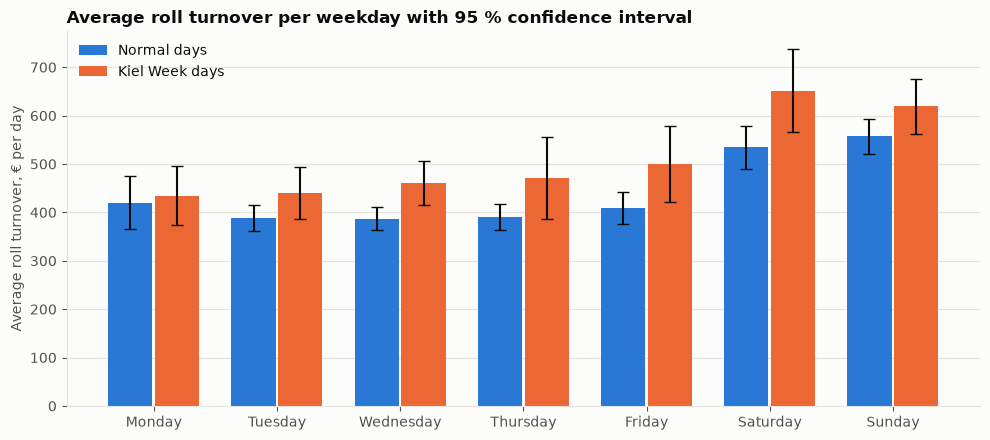

,Normal days,Kiel Week days,Mean normal (€),± CI normal,Mean Kiel Week (€),± CI Kiel Week,Difference (%),"p (Welch, one-sided)"
Weekday,,,,,,,,
Monday,20,5,420.0,55.0,435.0,62.0,3.5,0.339
Tuesday,19,5,389.0,27.0,439.0,54.0,13.0,0.030
Wednesday,20,5,387.0,24.0,461.0,46.0,19.0,0.003
Thursday,19,5,390.0,27.0,471.0,84.0,20.7,0.026
Friday,20,5,409.0,33.0,500.0,79.0,22.4,0.014
Saturday,20,10,534.0,44.0,651.0,86.0,21.9,0.009
Sunday,20,10,557.0,37.0,619.0,57.0,11.2,0.030


In [6]:
rows = []
for wd in WEEKDAYS:
    kw = rolls.loc[(rolls["Weekday"] == wd) & (rolls["Period"] == "Kiel Week"), "Umsatz"]
    nm = rolls.loc[(rolls["Weekday"] == wd) & (rolls["Period"] == "Normal"), "Umsatz"]
    (m_kw, ci_kw), (m_nm, ci_nm) = mean_ci(kw), mean_ci(nm)
    rows.append({
        "Weekday": wd, "Normal days": len(nm), "Kiel Week days": len(kw),
        "Mean normal (€)": m_nm, "± CI normal": ci_nm,
        "Mean Kiel Week (€)": m_kw, "± CI Kiel Week": ci_kw,
        "Difference (%)": 100 * (m_kw / m_nm - 1),
        "p (Welch, one-sided)": stats.ttest_ind(kw, nm, equal_var=False, alternative="greater").pvalue,
    })
by_weekday = pd.DataFrame(rows).set_index("Weekday")

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(WEEKDAYS))
w = 0.38
ax.bar(x - w / 2, by_weekday["Mean normal (€)"], width=w - 0.02, color=C_NORMAL, label="Normal days")
ax.bar(x + w / 2, by_weekday["Mean Kiel Week (€)"], width=w - 0.02, color=C_KW, label="Kiel Week days")
ax.errorbar(x - w / 2, by_weekday["Mean normal (€)"], yerr=by_weekday["± CI normal"],
            fmt="none", ecolor=INK, elinewidth=1.5, capsize=4)
ax.errorbar(x + w / 2, by_weekday["Mean Kiel Week (€)"], yerr=by_weekday["± CI Kiel Week"],
            fmt="none", ecolor=INK, elinewidth=1.5, capsize=4)
ax.grid(axis="x", visible=False)
ax.set_xticks(x, WEEKDAYS)
ax.set_ylabel("Average roll turnover, € per day")
ax.set_title("Average roll turnover per weekday with 95 % confidence interval", loc="left")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

by_weekday.round({"Mean normal (€)": 0, "± CI normal": 0, "Mean Kiel Week (€)": 0, "± CI Kiel Week": 0,
                  "Difference (%)": 1, "p (Welch, one-sided)": 3})

## 5. How to read the results, and limits

- **p-value:** if Kiel Week made no difference, how likely would a result at least this large be by pure chance? Below 0.05 we call it "significant".
- **Only 5 Kiel Weeks.** Every test here rests on 5 events. A single unusual year could change the picture.
- **Choice of normal days.** Roll sales rise strongly in the second half of July (summer holidays: about 400 € per day in June, about 600 € in late July). Our normal weeks lie close to Kiel Week and avoid most of that peak. A first try that used all June and July days as normal days found no clear effect, so the result depends on this choice.
- **Turnover, not demand.** On sold-out days turnover understates what customers wanted.
- **Association, not cause.** Something else in the same week could also play a part.

## 6. Conclusion

**Answer: yes. Rolls sold clearly more during Kiel Week, in every one of the 5 years.**

| Test | Result |
|---|---|
| **Whole weeks (main test)** | Kiel Week week vs. normal weeks: **+19.8 % on average** (2014 +19.7 %, 2015 +19.6 %, 2016 +27.9 %, 2017 +14.1 %, 2018 +17.7 %). Paired t-test, one-sided: **p = 0.0004**. |
| **Regression (cross-check)** | Kiel Week day vs. normal day of the same weekday and year: **+16.6 %** (95 % confidence interval +11.6 % to +21.9 %), p far below 0.05. |
| **Per weekday (detail)** | Higher on all 7 weekdays; strongest Wednesday to Saturday (+19 % to +22 %), weakest Monday (+3.5 %, not significant). |

- The two methods agree: Kiel Week brings roughly **+15 % to +20 %** more roll turnover per day.
- The week test is the most trustworthy, because it uses one value per Kiel Week and the weekday effect cancels. All 5 years point the same way, and the increase is never below +14 %.

**Limits:** only 5 Kiel Weeks; the result depends on comparing with nearby weeks (against the late-July holiday peak, Kiel Week would not stand out); turnover understates demand on sold-out days; association, not cause.

**For modelling:** `KielerWoche` is known in advance and is a useful feature for rolls, together with weekday. Because of the summer rise in July, a feature for the school summer holidays should be considered too, so that the model does not confuse the two effects.